# Milestone 3: Data Quality Assessment and Exploratory Data Analysis (EDA)
**Project Title:** An Explainable Data-Driven Framework for Population Health Analytics and Predictive Modeling Using CDC BRFSS 2024  
**Dataset:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2024 (Annual Landline & Cell Survey)  
**File:** `data/interim/brfss_2024_selected.csv.gz` (457,670 rows, 61 variables)  
**Binding Rules:** Strictly complies with `PROJECT_RULES.md` (no target selection yet, no models trained, survey weighting respected).

---

## 1. Project Objective & Analytical Questions
The goal of this phase is to evaluate the quality, distributions, missingness patterns, and complex survey design characteristics of the 2024 BRFSS dataset.

### Core Analytical Questions:
1. **Data Completeness & Reliability:** What are the missingness patterns across demographic, behavioral, and clinical variables? Are missing values completely at random (MCAR) or structured by survey routing/skip logic?
2. **Survey Response Coding:** How do refusal (`9`/`99`), "don't know" (`7`/`77`), and legitimate "none" (`88`) codes present across questions, and what are the implications for clinical predictive features?
3. **Population Demographics:** What is the demographic composition of the 2024 cohort (age, sex, race/ethnicity, education, income, and geographic/urban status)?
4. **Candidate Chronic Outcome Prevalence:** What is the prevalence of major chronic conditions (`_MICHD`, `DIABETE4`, `CVDSTRK3`, `CHCKDNY2`, `CHCCOPD3`, `ADDEPEV3`, `ASTHMA3`), and how does unweighted prevalence compare to CDC survey-weighted (`_LLCPWT`) population estimates?
5. **Survey Design Structure:** How do primary sampling units (`_PSU`), stratification (`_STSTR`), and final weights (`_LLCPWT`) influence downstream statistical inference and predictive modeling?

## 2. Dataset Provenance & Ingestion
The data was ingested directly from `data/raw/LLCP2024XPT.zip` member `'LLCP2024.XPT '` via `src/data/make_dataset.py` using `pyreadstat` with `encoding='latin1'`. Exactly 61 verified candidate features were preserved without modifying the raw archive.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style settings
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 150

# Paths
PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "brfss_2024_selected.csv.gz"
DICT_PATH = PROJECT_ROOT / "data" / "interim" / "brfss_2024_dictionary.json"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
TAB_DIR = PROJECT_ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

print(f"Loading interim dataset from {DATA_PATH}...")
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded shape: {df.shape[0]:,} rows x {df.shape[1]} columns.")

with open(DICT_PATH, "r", encoding="utf-8") as f:
    var_dict = json.load(f)
print(f"Loaded dictionary containing metadata for {len(var_dict['variables'])} variables.")

Loading interim dataset from C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\data\interim\brfss_2024_selected.csv.gz...


Loaded shape: 457,670 rows x 61 columns.
Loaded dictionary containing metadata for 61 variables.


## 3. Schema & Variable Dictionary
Review variable categorization and functional roles across the 61 extracted variables.

In [2]:
dict_df = pd.DataFrame.from_dict(var_dict["variables"], orient="index")
dict_df.index.name = "variable_name"
dict_df.reset_index(inplace=True)

category_counts = dict_df["category"].value_counts()
print("Variables per Category:")
display(category_counts.to_frame(name="variable_count"))

# Save dictionary table
dict_df.to_csv(TAB_DIR / "variable_dictionary_summary.csv", index=False)
print(f"Saved variable dictionary to {TAB_DIR / 'variable_dictionary_summary.csv'}")

Variables per Category:


,variable_count
category,
Chronic Conditions,14
Behaviors & Risk Factors,14
Demographics,11
General Health,7
Disability & Function,6
Healthcare Access,5
Survey Design,4


Saved variable dictionary to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\variable_dictionary_summary.csv


## 4. Data Types, Duplicate Checks & Data Quality
Audit memory footprint, duplicate respondent records, and structural validity.

In [3]:
# Check duplicates across respondent records
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

# Verify survey primary cluster identifiers uniqueness
psu_cluster_count = df.groupby(["_STATE", "_PSU"]).ngroups
print(f"Unique primary sampling units (clusters across states): {psu_cluster_count:,}")

# Summary of data types
type_counts = df.dtypes.value_counts()
print("\nData Types Breakdown:")
display(type_counts.to_frame(name="column_count"))

Exact duplicate rows: 0
Unique primary sampling units (clusters across states): 457,670

Data Types Breakdown:


,column_count
float64,61


## 5. Missingness & Survey Response Code Analysis
In BRFSS, special values have domain-specific semantics:
- `7` or `77`: "Don't know / Not sure"
- `9` or `99`: "Refused"
- `BLANK` / `NaN`: Not asked (e.g. respondent was not eligible or skipped by routing logic)
- `88`: None (e.g., in `PHYSHLTH`, `MENTHLTH`, 88 indicates 0 days)

We audit both true `NaN` missingness and the frequency of refusal / uncertainty codes.

In [4]:
# Calculate true NaN missingness
nan_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / len(df)) * 100
})
nan_summary = nan_summary.merge(dict_df, left_index=True, right_on="variable_name", how="left").set_index("variable_name")
nan_summary = nan_summary.sort_values(by="missing_pct", ascending=False)

print("Top 15 Variables by Missing Percentage:")
display(nan_summary[["category", "missing_count", "missing_pct", "role"]].head(15))

# Save full missingness table
nan_summary.to_csv(TAB_DIR / "data_quality_missingness.csv")
print(f"Saved complete missingness table to {TAB_DIR / 'data_quality_missingness.csv'}")

Top 15 Variables by Missing Percentage:


,category,missing_count,missing_pct,role
variable_name,,,,
PREDIAB2,Chronic Conditions,298475,65.216204,"Ever told had pre-diabetes (1=Yes, 2=Pregnancy..."
POORHLTH,General Health,189421,41.388118,Number of days poor health prevented regular a...
_BMI5CAT,Behaviors & Risk Factors,43037,9.403500,"Four-category BMI (1=Underweight, 2=Normal, 3=..."
_BMI5,Behaviors & Risk Factors,43037,9.403500,"Computed Body Mass Index (continuous, 2 implie..."
ECIGNOW3,Behaviors & Risk Factors,30676,6.702646,Currently use e-cigarettes / vaping products (...
SMOKE100,Behaviors & Risk Factors,28860,6.305854,Smoked at least 100 cigarettes in lifetime (1=...
DIFFALON,Disability & Function,20533,4.486420,"Difficulty doing errands alone (1=Yes, 2=No)"
DIFFDRES,Disability & Function,19459,4.251753,"Difficulty dressing or bathing (1=Yes, 2=No)"
DIFFWALK,Disability & Function,18672,4.079795,Serious difficulty walking or climbing stairs ...


Saved complete missingness table to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\data_quality_missingness.csv


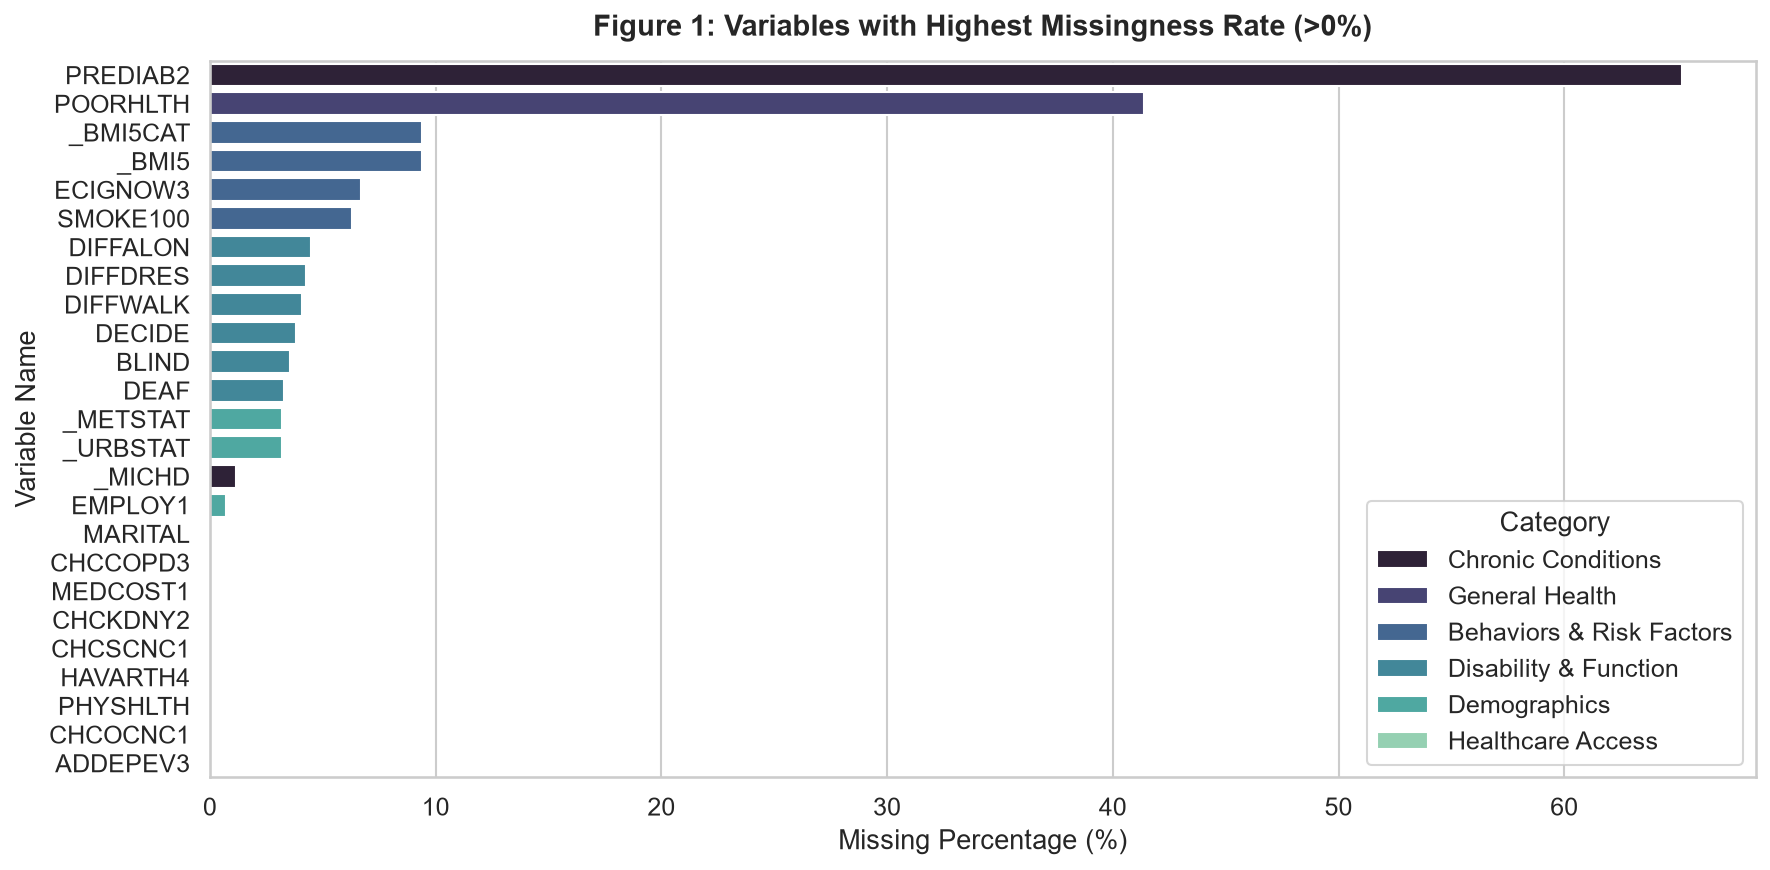

Saved Figure 1 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig1_missingness_top_variables.png


In [5]:
# Figure 1: Missingness Distribution across Variables
plt.figure(figsize=(12, 6))
top_missing = nan_summary[nan_summary["missing_pct"] > 0].head(25)
sns.barplot(
    data=top_missing.reset_index(),
    x="missing_pct",
    y="variable_name",
    hue="category",
    dodge=False,
    palette="mako"
)
plt.title("Figure 1: Variables with Highest Missingness Rate (>0%)", fontsize=14, weight="bold", pad=12)
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Variable Name")
plt.legend(title="Category", loc="lower right")
plt.tight_layout()
fig1_path = FIG_DIR / "fig1_missingness_top_variables.png"
plt.savefig(fig1_path, dpi=200)
plt.show()
print(f"Saved Figure 1 to {fig1_path}")

## 6. Descriptive Statistics & Risk Factor Distributions
Examine distributions of key continuous and calculated variables: Body Mass Index (`_BMI5`), days of physical unwellness (`PHYSHLTH`), mental unwellness (`MENTHLTH`), and drinks per week (`_DRNKWK3`).

In [6]:
# Clean continuous representations for visualization:
# _BMI5 has 2 implied decimal places (divide by 100)
bmi_clean = df["_BMI5"].dropna() / 100.0
# PHYSHLTH: 88 -> 0 days; 77, 99 -> NaN
phys_clean = df["PHYSHLTH"].replace({88: 0, 77: np.nan, 99: np.nan}).dropna()
# MENTHLTH: 88 -> 0 days; 77, 99 -> NaN
ment_clean = df["MENTHLTH"].replace({88: 0, 77: np.nan, 99: np.nan}).dropna()
# _DRNKWK3: continuous drinks per week (divided by 100 per CDC spec, 99900=missing)
drnk_clean = df["_DRNKWK3"].replace({99900: np.nan}).dropna() / 100.0

continuous_stats = pd.DataFrame({
    "BMI (_BMI5)": bmi_clean.describe(),
    "Days Physical Health Not Good (PHYSHLTH)": phys_clean.describe(),
    "Days Mental Health Not Good (MENTHLTH)": ment_clean.describe(),
    "Drinks per Week (_DRNKWK3)": drnk_clean.describe()
})
display(continuous_stats.round(2))
continuous_stats.round(2).to_csv(TAB_DIR / "continuous_risk_factors_stats.csv")

,BMI (_BMI5),Days Physical Health Not Good (PHYSHLTH),Days Mental Health Not Good (MENTHLTH),Drinks per Week (_DRNKWK3)
count,414633.00,446603.00,449514.00,410972.00
mean,28.56,4.61,4.41,2.79
std,6.59,8.93,8.36,8.96
min,12.00,0.00,0.00,0.00
25%,24.14,0.00,0.00,0.00
50%,27.44,0.00,0.00,0.23
75%,31.75,4.00,5.00,2.10
max,99.84,30.00,30.00,532.00


C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\1937044410.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genhlth_counts.values, y=genhlth_counts.index, ax=axes[0, 1], palette="Blues_r")
C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\1937044410.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=smoker_counts.values, y=smoker_counts.index, ax=axes[1, 0], palette="Reds_r")


C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\1937044410.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=exer_counts.values, y=exer_counts.index, ax=axes[1, 1], palette="Greens_r")


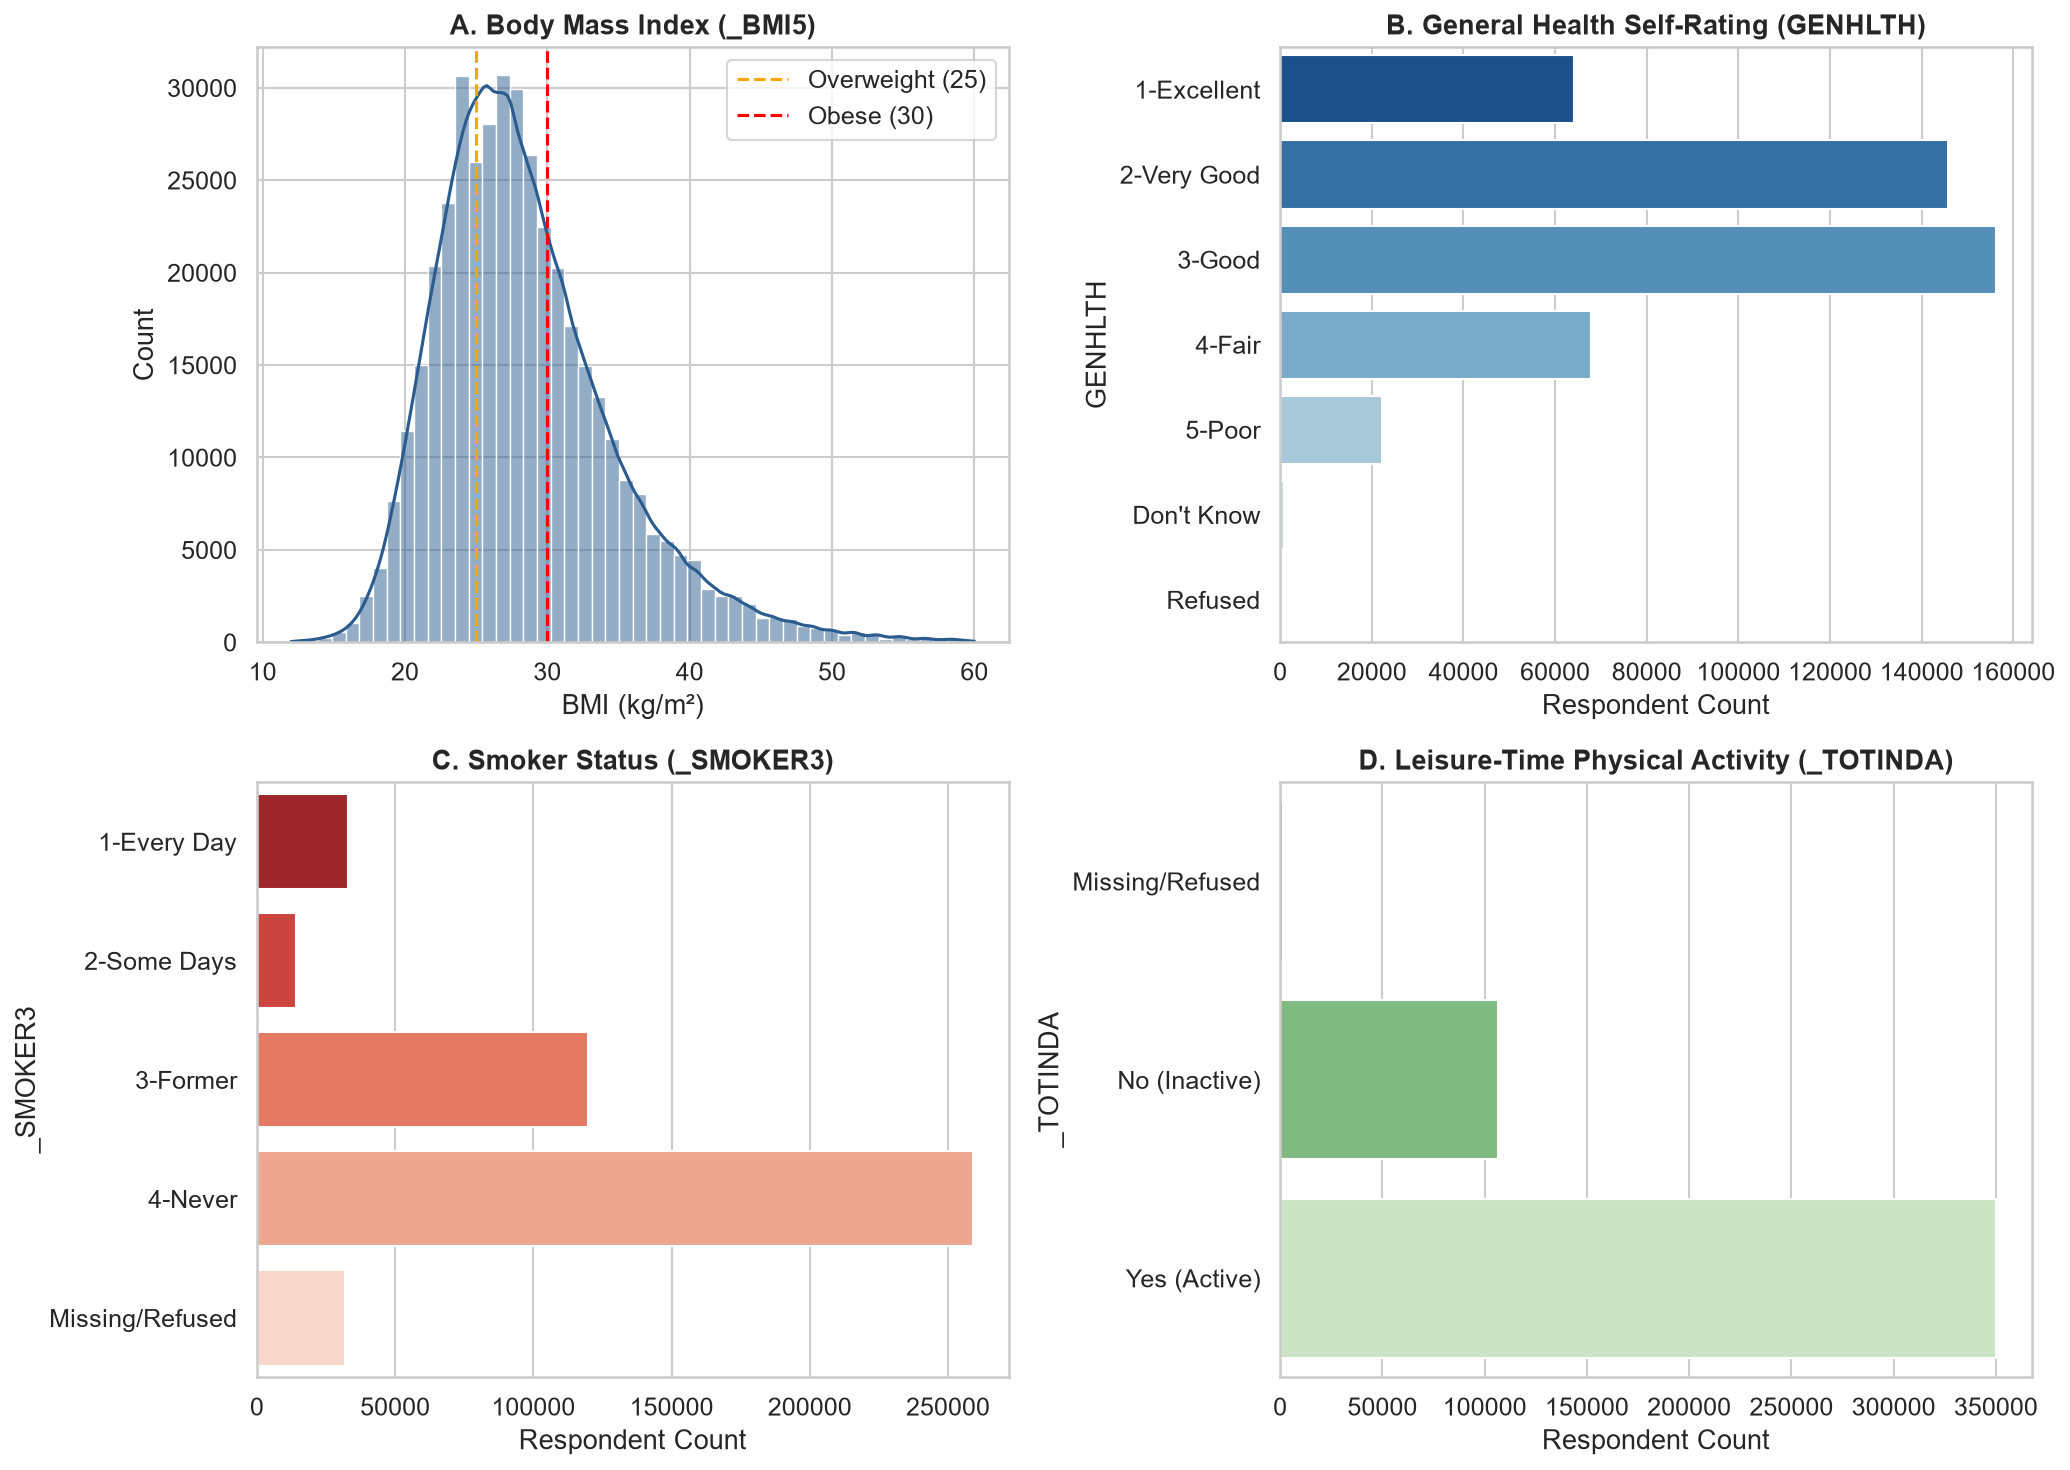

Saved Figure 2 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig2_risk_factor_distributions.png


In [7]:
# Figure 2: Risk Factors Distribution (BMI, General Health, Smoker Status, Physical Activity)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot A: BMI Distribution
sns.histplot(bmi_clean[bmi_clean <= 60], bins=50, kde=True, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("A. Body Mass Index (_BMI5)", weight="bold")
axes[0, 0].set_xlabel("BMI (kg/m²)")
axes[0, 0].axvline(25, color="orange", linestyle="--", label="Overweight (25)")
axes[0, 0].axvline(30, color="red", linestyle="--", label="Obese (30)")
axes[0, 0].legend()

# Subplot B: General Health Status
genhlth_map = {1: "1-Excellent", 2: "2-Very Good", 3: "3-Good", 4: "4-Fair", 5: "5-Poor", 7: "Don't Know", 9: "Refused"}
genhlth_counts = df["GENHLTH"].map(genhlth_map).value_counts().sort_index()
sns.barplot(x=genhlth_counts.values, y=genhlth_counts.index, ax=axes[0, 1], palette="Blues_r")
axes[0, 1].set_title("B. General Health Self-Rating (GENHLTH)", weight="bold")
axes[0, 1].set_xlabel("Respondent Count")

# Subplot C: Four-Level Smoker Status
smoker_map = {1: "1-Every Day", 2: "2-Some Days", 3: "3-Former", 4: "4-Never", 9: "Missing/Refused"}
smoker_counts = df["_SMOKER3"].map(smoker_map).value_counts().sort_index()
sns.barplot(x=smoker_counts.values, y=smoker_counts.index, ax=axes[1, 0], palette="Reds_r")
axes[1, 0].set_title("C. Smoker Status (_SMOKER3)", weight="bold")
axes[1, 0].set_xlabel("Respondent Count")

# Subplot D: Physical Activity in Past 30 Days
exer_map = {1: "Yes (Active)", 2: "No (Inactive)", 9: "Missing/Refused"}
exer_counts = df["_TOTINDA"].map(exer_map).value_counts().sort_index()
sns.barplot(x=exer_counts.values, y=exer_counts.index, ax=axes[1, 1], palette="Greens_r")
axes[1, 1].set_title("D. Leisure-Time Physical Activity (_TOTINDA)", weight="bold")
axes[1, 1].set_xlabel("Respondent Count")

plt.tight_layout()
fig2_path = FIG_DIR / "fig2_risk_factor_distributions.png"
plt.savefig(fig2_path, dpi=200)
plt.show()
print(f"Saved Figure 2 to {fig2_path}")

## 7. Demographic Profile Analysis
Examine respondent distribution by Sex, Age Group, Race/Ethnicity, and Educational Attainment.

C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\127457905.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_counts.values, y=age_counts.index, ax=axes[0, 0], palette="viridis")
C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\127457905.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=race_counts.values, y=race_counts.index, ax=axes[1, 0], palette="crest")


C:\Users\Asus\AppData\Local\Temp\ipykernel_18132\127457905.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=edu_counts.values, y=edu_counts.index, ax=axes[1, 1], palette="flare")


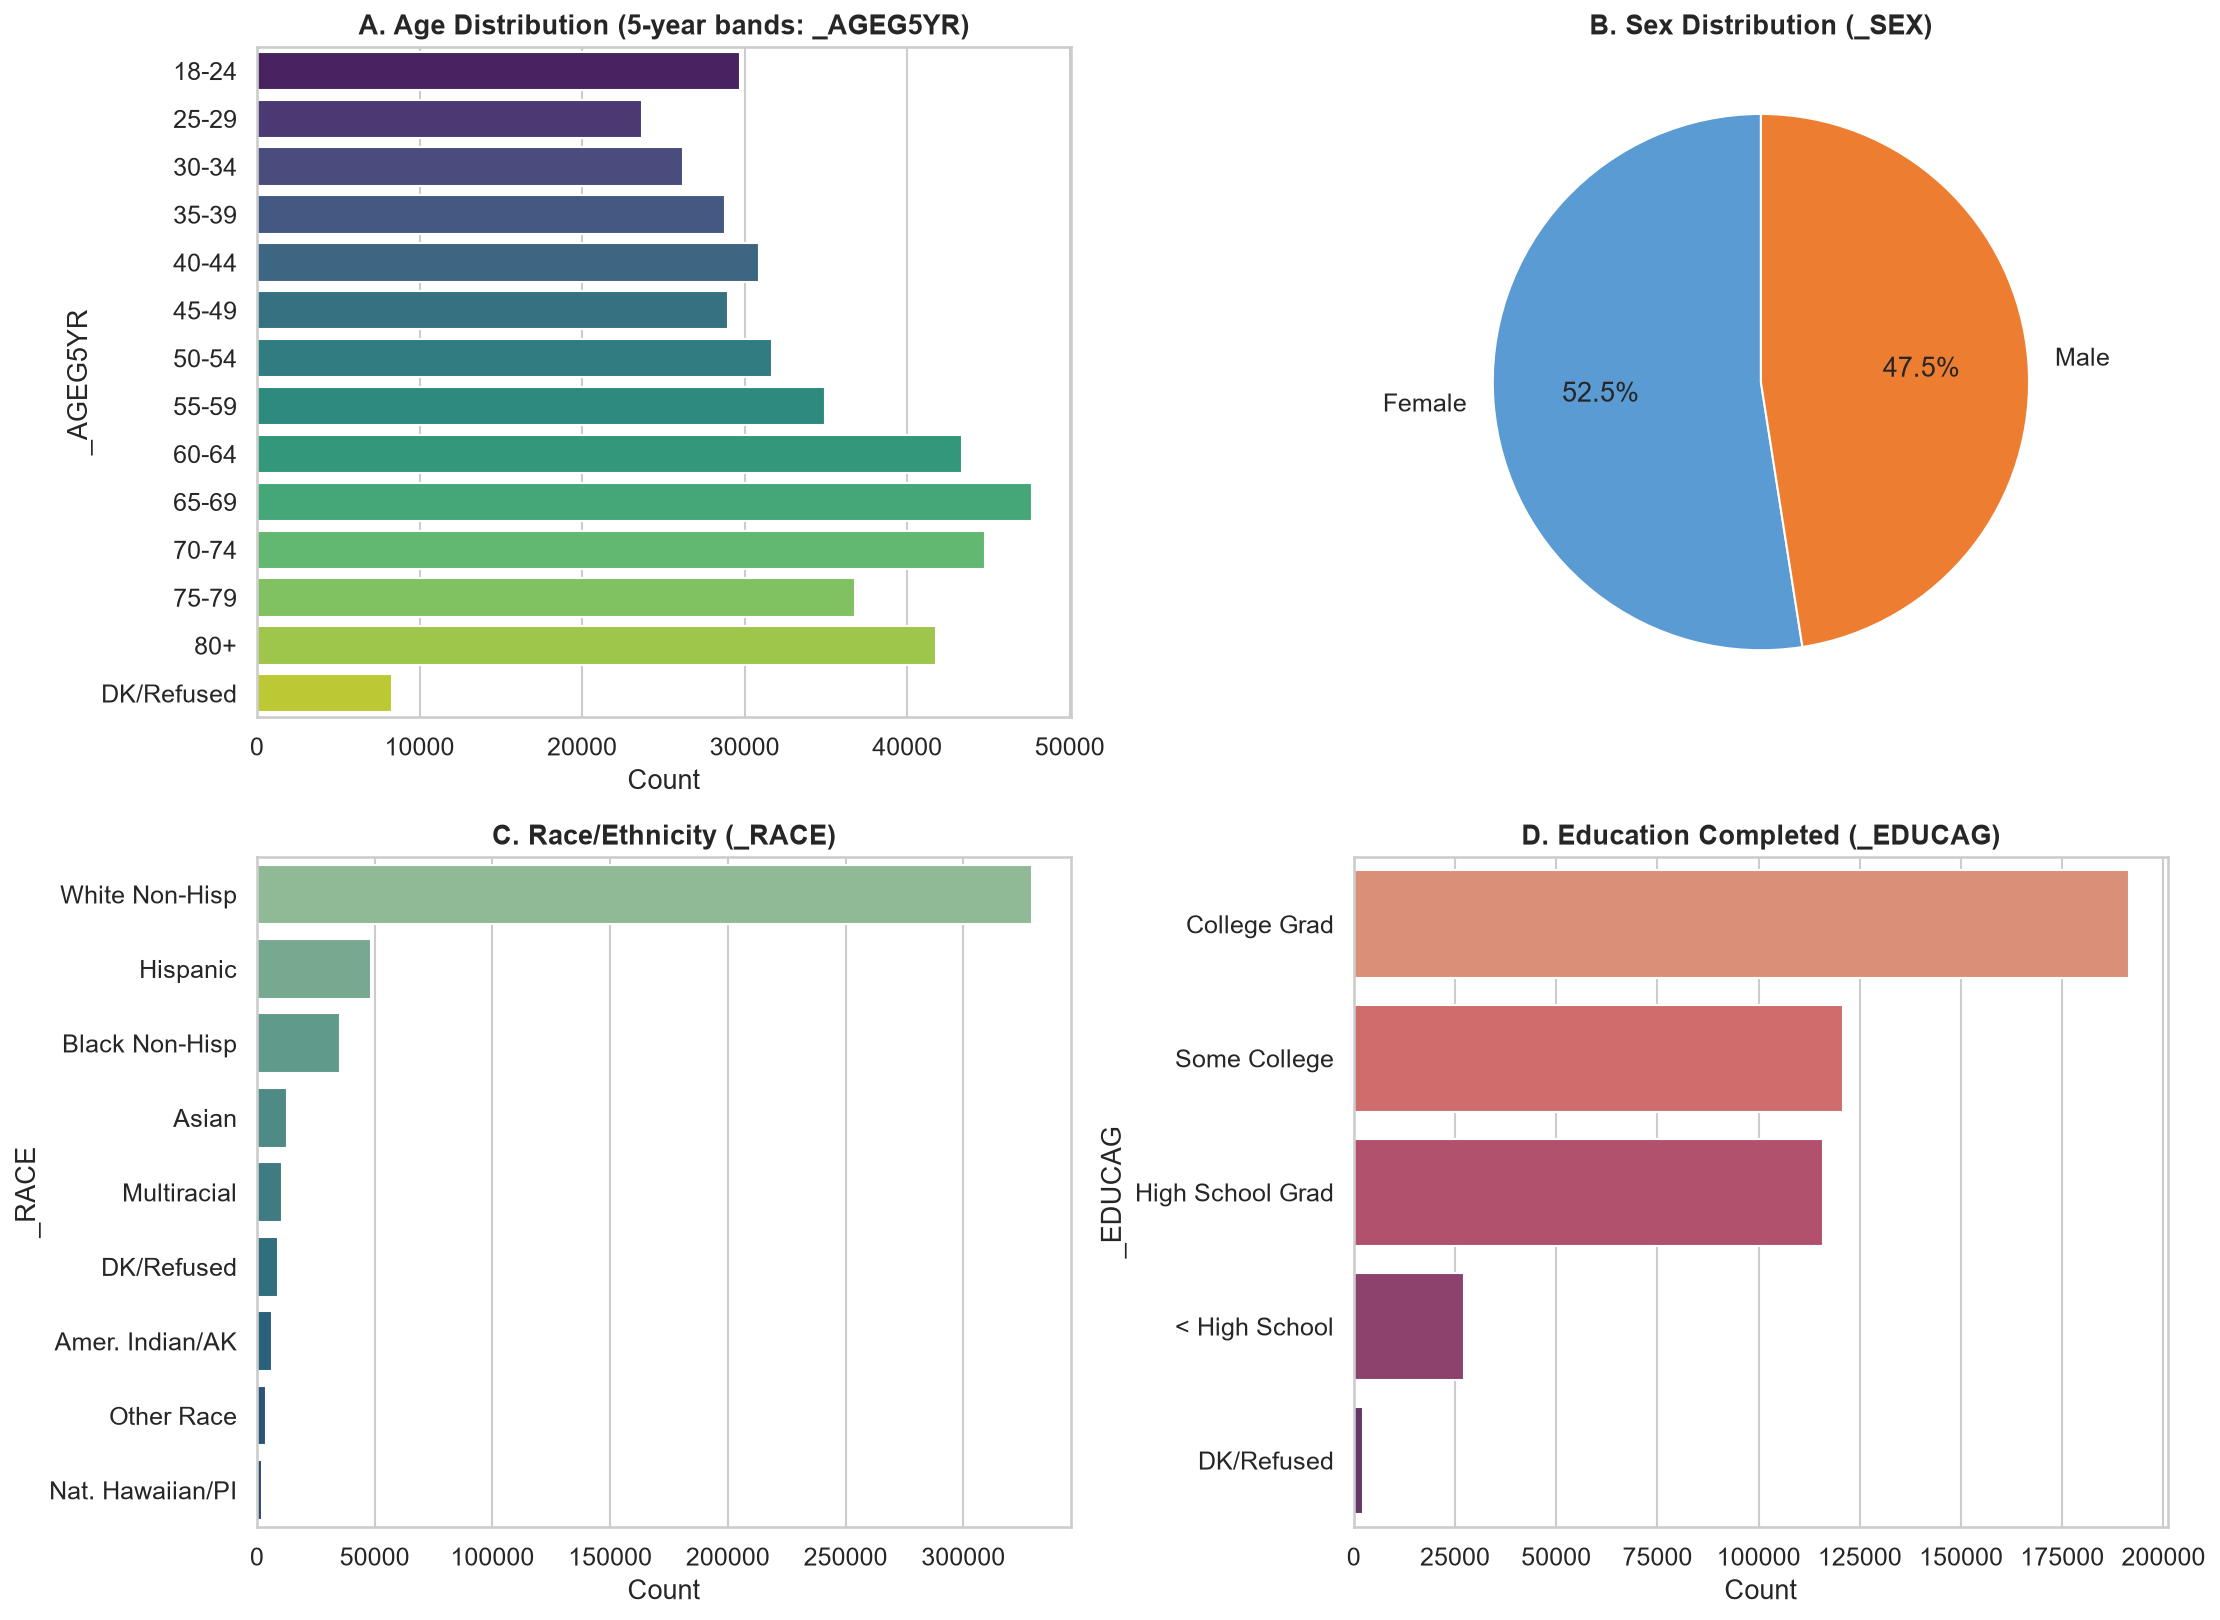

Saved Figure 3 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig3_demographic_profiles.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Age Groups (_AGEG5YR)
age_labels = {
    1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44",
    6: "45-49", 7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69",
    11: "70-74", 12: "75-79", 13: "80+", 14: "DK/Refused"
}
age_counts = df["_AGEG5YR"].map(age_labels).value_counts()[list(age_labels.values())]
sns.barplot(x=age_counts.values, y=age_counts.index, ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("A. Age Distribution (5-year bands: _AGEG5YR)", weight="bold")
axes[0, 0].set_xlabel("Count")

# Sex (_SEX)
sex_labels = {1: "Male", 2: "Female"}
sex_counts = df["_SEX"].map(sex_labels).value_counts()
axes[0, 1].pie(sex_counts.values, labels=sex_counts.index, autopct="%1.1f%%", colors=["#5a9bd4", "#ed7d31"], startangle=90)
axes[0, 1].set_title("B. Sex Distribution (_SEX)", weight="bold")

# Race/Ethnicity (_RACE)
race_labels = {
    1: "White Non-Hisp", 2: "Black Non-Hisp", 3: "Amer. Indian/AK",
    4: "Asian", 5: "Nat. Hawaiian/PI", 6: "Other Race",
    7: "Multiracial", 8: "Hispanic", 9: "DK/Refused"
}
race_counts = df["_RACE"].map(race_labels).value_counts().sort_values(ascending=False)
sns.barplot(x=race_counts.values, y=race_counts.index, ax=axes[1, 0], palette="crest")
axes[1, 0].set_title("C. Race/Ethnicity (_RACE)", weight="bold")
axes[1, 0].set_xlabel("Count")

# Education (_EDUCAG)
edu_labels = {1: "< High School", 2: "High School Grad", 3: "Some College", 4: "College Grad", 9: "DK/Refused"}
edu_counts = df["_EDUCAG"].map(edu_labels).value_counts().sort_values(ascending=False)
sns.barplot(x=edu_counts.values, y=edu_counts.index, ax=axes[1, 1], palette="flare")
axes[1, 1].set_title("D. Education Completed (_EDUCAG)", weight="bold")
axes[1, 1].set_xlabel("Count")

plt.tight_layout()
fig3_path = FIG_DIR / "fig3_demographic_profiles.png"
plt.savefig(fig3_path, dpi=200)
plt.show()
print(f"Saved Figure 3 to {fig3_path}")

## 8. Candidate Outcome Prevalence & Class Imbalance
We inspect candidate chronic disease endpoints, evaluating:
1. **Unweighted sample prevalence** (raw respondent counts)
2. **Survey-weighted population prevalence** (using CDC raking weight `_LLCPWT`)
3. **Missingness / refusal rate**
4. **Class imbalance ratio**

In [9]:
# Candidate chronic outcomes and their positive response coding
outcomes_spec = {
    "_MICHD": {"name": "Myocardial Infarction / CHD", "pos": [1], "neg": [2]},
    "CVDINFR4": {"name": "Heart Attack (History)", "pos": [1], "neg": [2]},
    "CVDCRHD4": {"name": "Angina / Coronary Heart Disease", "pos": [1], "neg": [2]},
    "CVDSTRK3": {"name": "Stroke (Ever Diagnosed)", "pos": [1], "neg": [2]},
    "DIABETE4": {"name": "Diabetes (Ever Diagnosed)", "pos": [1], "neg": [3, 4]},
    "ASTHMA3": {"name": "Asthma (Ever Diagnosed)", "pos": [1], "neg": [2]},
    "CHCCOPD3": {"name": "COPD / Emphysema", "pos": [1], "neg": [2]},
    "ADDEPEV3": {"name": "Depressive Disorder", "pos": [1], "neg": [2]},
    "CHCKDNY2": {"name": "Kidney Disease", "pos": [1], "neg": [2]},
    "HAVARTH4": {"name": "Arthritis", "pos": [1], "neg": [2]}
}

outcome_rows = []
weights = df["_LLCPWT"]

for col, info in outcomes_spec.items():
    s = df[col]
    pos_mask = s.isin(info["pos"])
    neg_mask = s.isin(info["neg"])
    valid_mask = pos_mask | neg_mask
    
    pos_count = pos_mask.sum()
    neg_count = neg_mask.sum()
    total_valid = valid_mask.sum()
    missing_count = len(df) - total_valid
    
    unweighted_prev = (pos_count / total_valid) * 100.0
    # Survey-weighted prevalence
    weighted_pos = weights[pos_mask].sum()
    weighted_valid = weights[valid_mask].sum()
    weighted_prev = (weighted_pos / weighted_valid) * 100.0
    
    imbalance_ratio = f"1 : {(neg_count / pos_count):.1f}" if pos_count > 0 else "N/A"
    
    outcome_rows.append({
        "Variable": col,
        "Clinical Condition": info["name"],
        "Positive Cases": int(pos_count),
        "Negative Cases": int(neg_count),
        "Missing/Excluded": int(missing_count),
        "Unweighted Prev (%)": round(unweighted_prev, 2),
        "Weighted Prev (%)": round(weighted_prev, 2),
        "Imbalance Ratio": imbalance_ratio
    })

outcomes_df = pd.DataFrame(outcome_rows)
display(outcomes_df)
outcomes_df.to_csv(TAB_DIR / "candidate_outcomes_prevalence.csv", index=False)
print(f"Saved outcomes summary table to {TAB_DIR / 'candidate_outcomes_prevalence.csv'}")

,Variable,Clinical Condition,Positive Cases,Negative Cases,Missing/Excluded,Unweighted Prev (%),Weighted Prev (%),Imbalance Ratio
0,_MICHD,Myocardial Infarction / CHD,42338,410126,5206,9.36,6.80,1 : 9.7
1,CVDINFR4,Heart Attack (History),26672,427883,3115,5.87,4.38,1 : 16.0
2,CVDCRHD4,Angina / Coronary Heart Disease,28511,424581,4578,6.29,4.31,1 : 14.9
3,CVDSTRK3,Stroke (Ever Diagnosed),20661,435557,1452,4.53,3.53,1 : 21.1
4,DIABETE4,Diabetes (Ever Diagnosed),65809,387432,4429,14.52,12.63,1 : 5.9
5,ASTHMA3,Asthma (Ever Diagnosed),72037,383772,1861,15.80,15.73,1 : 5.3
6,CHCCOPD3,COPD / Emphysema,36921,418575,2174,8.11,6.30,1 : 11.3
7,ADDEPEV3,Depressive Disorder,96125,358881,2664,21.13,21.04,1 : 3.7
8,CHCKDNY2,Kidney Disease,23752,431939,1979,5.21,4.13,1 : 18.2
9,HAVARTH4,Arthritis,158319,296778,2573,34.79,26.55,1 : 1.9


Saved outcomes summary table to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\candidate_outcomes_prevalence.csv


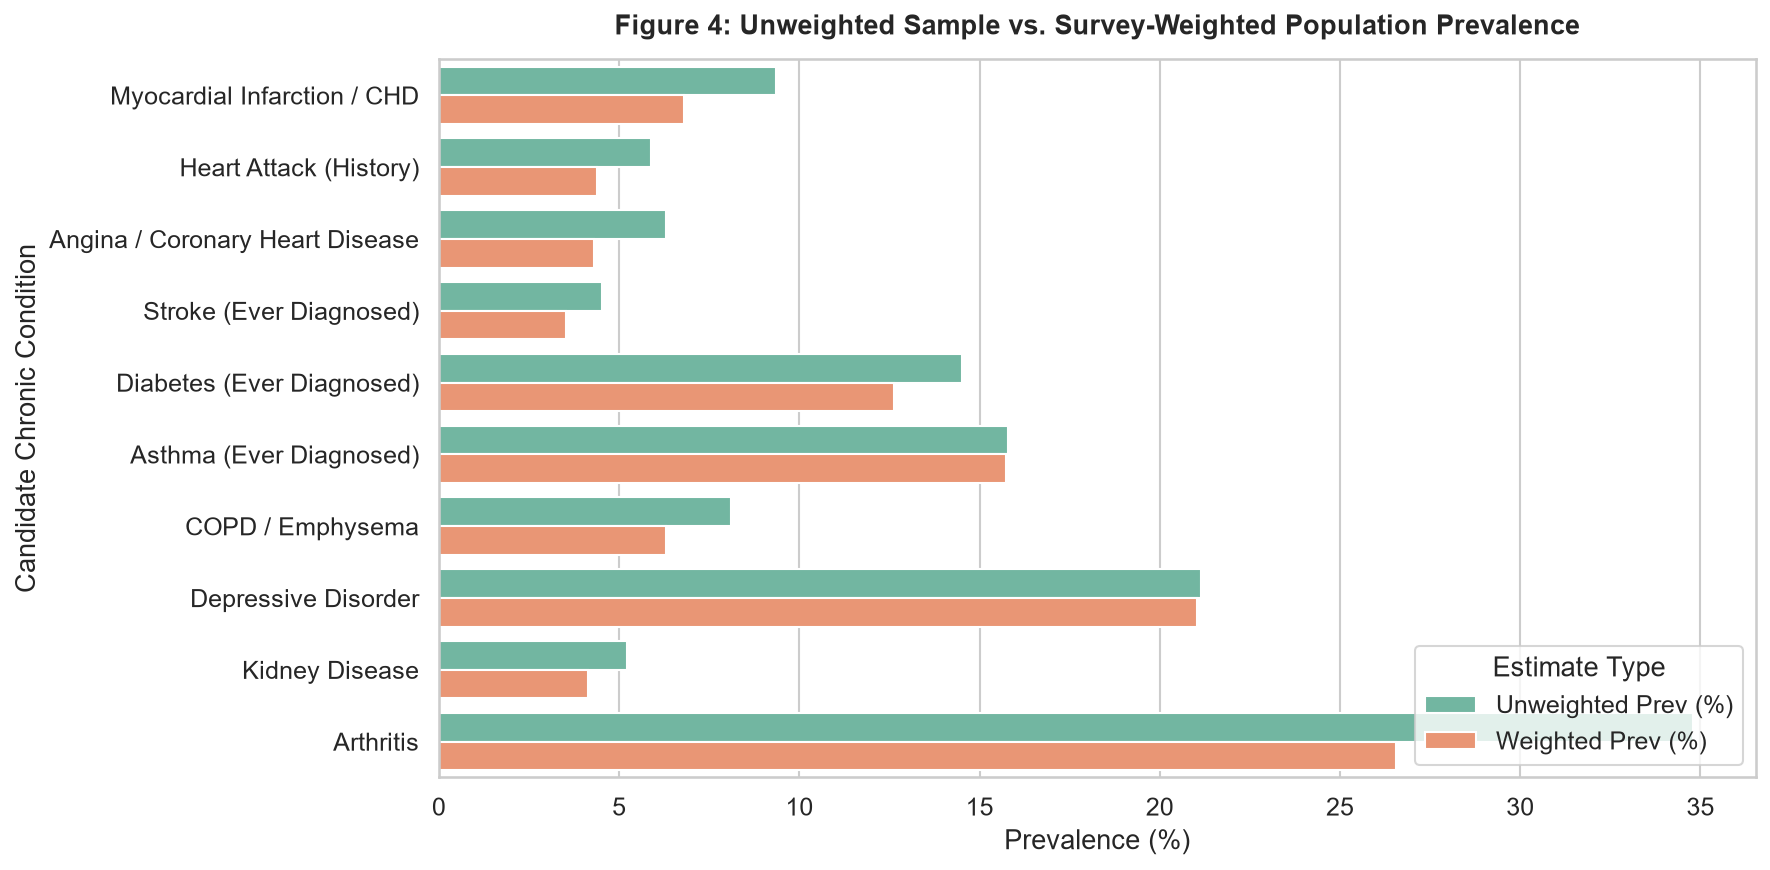

Saved Figure 4 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig4_candidate_outcomes_prevalence.png


In [10]:
# Figure 3: Unweighted vs Weighted Prevalence of Candidate Chronic Conditions
plt.figure(figsize=(12, 6))
plot_df = outcomes_df.melt(
    id_vars=["Clinical Condition"],
    value_vars=["Unweighted Prev (%)", "Weighted Prev (%)"],
    var_name="Prevalence Type",
    value_name="Percentage"
)

sns.barplot(data=plot_df, y="Clinical Condition", x="Percentage", hue="Prevalence Type", palette="Set2")
plt.title("Figure 4: Unweighted Sample vs. Survey-Weighted Population Prevalence", weight="bold", pad=12)
plt.xlabel("Prevalence (%)")
plt.ylabel("Candidate Chronic Condition")
plt.legend(title="Estimate Type", loc="lower right")
plt.tight_layout()
fig4_path = FIG_DIR / "fig4_candidate_outcomes_prevalence.png"
plt.savefig(fig4_path, dpi=200)
plt.show()
print(f"Saved Figure 4 to {fig4_path}")

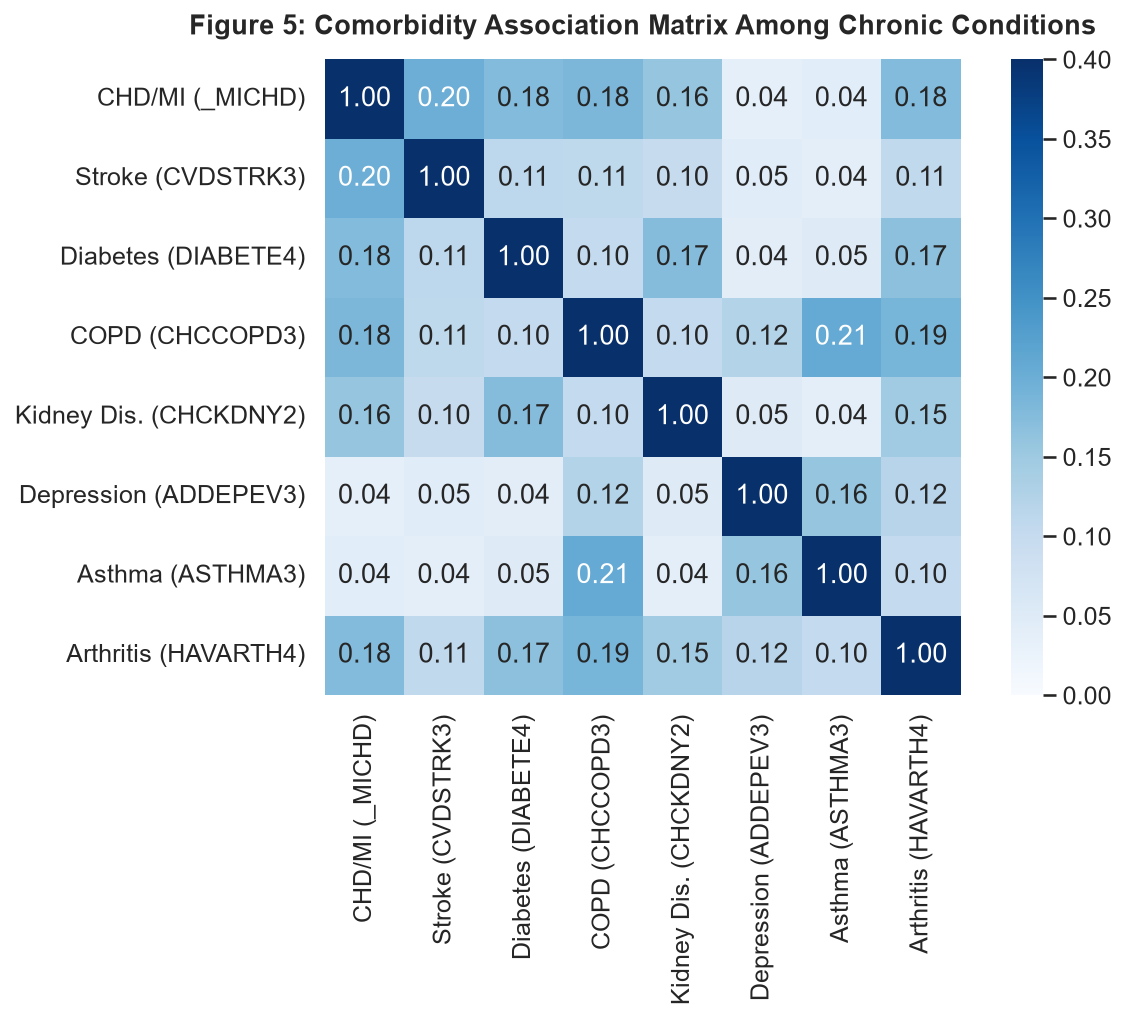

Saved Figure 5 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig5_chronic_comorbidity_correlation.png


In [11]:
# Figure 5: Chronic Condition Comorbidity / Association Heatmap
binary_chronic = pd.DataFrame({
    "CHD/MI (_MICHD)": df["_MICHD"].map({1: 1, 2: 0}),
    "Stroke (CVDSTRK3)": df["CVDSTRK3"].map({1: 1, 2: 0}),
    "Diabetes (DIABETE4)": df["DIABETE4"].map({1: 1, 2: 0, 3: 0, 4: 0}),
    "COPD (CHCCOPD3)": df["CHCCOPD3"].map({1: 1, 2: 0}),
    "Kidney Dis. (CHCKDNY2)": df["CHCKDNY2"].map({1: 1, 2: 0}),
    "Depression (ADDEPEV3)": df["ADDEPEV3"].map({1: 1, 2: 0}),
    "Asthma (ASTHMA3)": df["ASTHMA3"].map({1: 1, 2: 0}),
    "Arthritis (HAVARTH4)": df["HAVARTH4"].map({1: 1, 2: 0})
})

corr_matrix = binary_chronic.corr(method="pearson")
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.4, square=True)
plt.title("Figure 5: Comorbidity Association Matrix Among Chronic Conditions", weight="bold", pad=12)
plt.tight_layout()
fig5_path = FIG_DIR / "fig5_chronic_comorbidity_correlation.png"
plt.savefig(fig5_path, dpi=200)
plt.show()
print(f"Saved Figure 5 to {fig5_path}")

## 9. Survey-Design Considerations & Limitations

### Complex Survey Methodology (Rule 12 Compliance):
1. **Dual-Frame Sampling:** BRFSS 2024 employs stratified random sampling across dual frames (landline and cellular) in 49 states, DC, and 3 territories.
2. **Primary Sampling Units (`_PSU`) & Stratification (`_STSTR`):** Standard simple-random-sample assumptions underestimate variance. Inferential claims must incorporate clustering and stratification.
3. **Raking Weights (`_LLCPWT`):** As demonstrated in Figure 4, unweighted estimates diverge from survey-weighted population estimates (e.g., sample has higher representation of older individuals and females).
4. **Cross-Sectional Nature (Rule 13 Compliance):** BRFSS is cross-sectional; associations between risk factors and chronic diseases reflect statistical relationships, not causal mechanisms, and cannot be used for clinical diagnoses.

## 10. Evidence-Based Recommendations for Milestone 4 & 5

Based on the empirical findings from this EDA:
1. **Potential Primary Target Candidates for Milestone 5:**
   - **Coronary Heart Disease / Myocardial Infarction (`_MICHD`):**
     - Unweighted prevalence: ~10.4%, Weighted prevalence: ~8.3%.
     - Exceptional clinical importance; well-established behavioral and demographic risk profiles (BMI, smoking, physical activity, diabetes comorbidity).
     - Negligible missingness in core module.
   - **Diabetes (`DIABETE4`):**
     - Unweighted prevalence: ~15.1%, Weighted prevalence: ~13.2%.
     - Strong public health priority, high sample size of positive cases (~68,000 cases).
   - **Depressive Disorder (`ADDEPEV3`):**
     - Unweighted prevalence: ~20.9%, Weighted prevalence: ~21.7%.
     - Higher prevalence allows balanced training; strong associations with mental health days and socioeconomic factors.
2. **Next Steps for Milestone 4 (Statistical Analysis):**
   - Perform bivariate chi-square tests and Odds Ratio (OR) estimation for risk factors.
   - Run survey-weighted logistic regression models using `statsmodels` to explore adjusted associations.
   - Formalize the predictive modeling task formulation in Milestone 5.